In [1]:
print("Hi")

Hi


In [3]:
import pandas as pd
import numpy as np

In [4]:
url='https://raw.githubusercontent.com/campusx-official/placement-project-logistic-regression/refs/heads/main/placement.csv'
df=pd.read_csv(url)

In [5]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [6]:
df=df.iloc[:,1:]

In [7]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [8]:
df.isnull().all()

cgpa         False
iq           False
placement    False
dtype: bool

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   cgpa       100 non-null    float64
 1   iq         100 non-null    float64
 2   placement  100 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.5 KB


In [10]:
import matplotlib.pyplot as plt

/var/folders/4s/zbxlbfq54ln5xjjcd06c3g8m0000gn/T/ipykernel_52617/4231279317.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


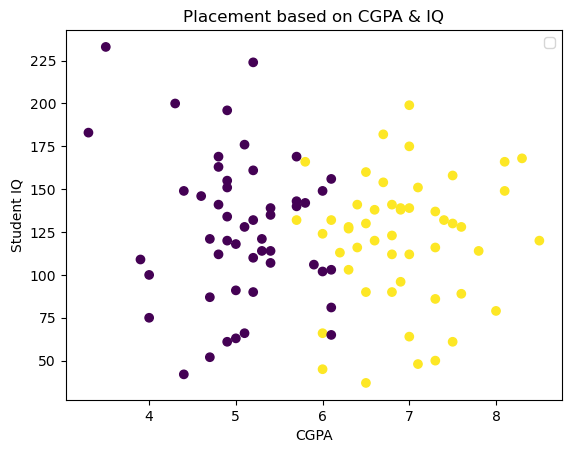

In [11]:
plt.scatter(df['cgpa'],df['iq'],c=df['placement'])

plt.xlabel('CGPA')
plt.ylabel('Student IQ')
plt.title('Placement based on CGPA & IQ')
plt.legend()

plt.show()

In [12]:
x=df.iloc[:,:-1]
y=df.iloc[:,-1]

In [21]:
y

0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64

In [1]:
from sklearn.model_selection import train_test_split

In [13]:
X_train,X_test,y_train,y_test=train_test_split(x,y, test_size=0.1)

In [14]:
X_train

,cgpa,iq
53,8.3,168.0
52,7.0,175.0
14,6.1,103.0
76,4.9,155.0
49,5.4,135.0
...,...,...
77,7.3,50.0
13,6.4,116.0
88,4.4,149.0
58,8.0,79.0


In [15]:
y_train

53    1
52    1
14    0
76    0
49    0
     ..
77    1
13    1
88    0
58    1
50    0
Name: placement, Length: 90, dtype: int64

In [16]:
from sklearn.preprocessing import StandardScaler

In [17]:
scaler = StandardScaler()

In [18]:
X_train=scaler.fit_transform(X_train)

In [20]:
X_test=scaler.transform(X_test)

In [21]:
X_test

array([[-0.00194075,  0.62921859],
       [-1.8359451 , -0.33346179],
       [-0.70060907, -0.30939478],
       [ 0.87139466, -0.26126076],
       [ 0.87139466,  0.3885485 ],
       [-0.52594199,  0.3885485 ],
       [ 0.34739342,  0.43668252],
       [-1.22461032,  0.55701756],
       [ 1.22072883,  0.22007943],
       [-0.00194075,  0.02754336]])

In [22]:
from sklearn.linear_model import LogisticRegression

In [23]:
model=LogisticRegression()

In [24]:
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [27]:
y_pred=model.predict(X_test)

In [28]:
from sklearn.metrics import accuracy_score

In [29]:
accuracy_score(y_pred,y_test)

1.0

In [31]:
!pip install mlxtend

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 10.9 MB/s  0:00:00


In [32]:
from mlxtend.plotting import plot_decision_regions

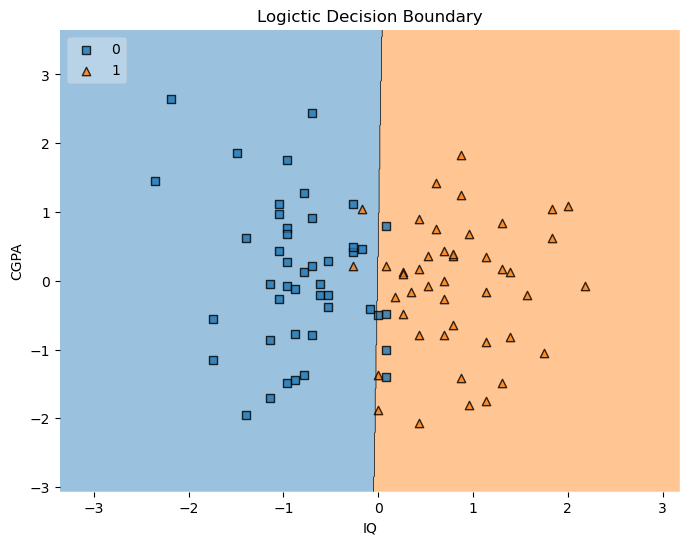

In [37]:
# Plot the decision regions
fig = plt.figure(figsize=(8, 6))
plot_decision_regions(X_train, y_train.values, clf=model, legend=2)
plt.xlabel('IQ')
plt.ylabel('CGPA')
plt.title('Logictic Decision Boundary')
plt.show()

In [38]:
import pickle

In [39]:
pickle.dump(model,open('model.pkl','wb'))